# 小实验：随便打乱 vs 同类内打乱

场景：网店销量受 **是否节假日**、**广告投放**、**价格** 影响。节假日广告投得多，平时投得少。

目标：亲手看到“随便打乱”会把广告的重要性夸大多少。

**用法**：从上到下，每个格子点左边的 ▶ 运行。

## 第1步：导入工具
Colab 已经装好了这些包，不需要安装。

In [1]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

rng = np.random.default_rng(0)  # 固定随机种子，保证每次结果一样

## 第2步：造一份假数据（1000天）
因为是我们自己造的，所以知道“真实规律”：节假日+150件，广告每多1单位+2件，价格每贵1元-3件。

In [2]:
n = 1000
holiday = rng.binomial(1, 0.3, n)                                      # 30%的日子是节假日
ad = np.where(holiday == 1, rng.normal(80, 10, n), rng.normal(20, 5, n))  # 节假日广告多，平时少
price = rng.normal(50, 5, n)
sales = 250 + 150*holiday + 2*ad - 3*price + rng.normal(0, 10, n)        # 真实规律 + 一点随机噪声

df = pd.DataFrame({'holiday': holiday, 'ad': ad, 'price': price, 'sales': sales})
df.head()

,holiday,ad,price,sales
0,0,21.064262,51.864477,128.597150
1,0,15.337299,52.907987,132.406086
2,0,18.263224,43.298896,169.031155
3,0,22.672265,46.699106,146.229985
4,1,65.956715,52.582476,394.232817


## 第3步：训练一个模型
用随机森林，根据三个变量猜销量。

In [3]:
X = df[['holiday', 'ad', 'price']]
y = df['sales']
model = RandomForestRegressor(n_estimators=200, random_state=0).fit(X, y)
base_error = mean_squared_error(y, model.predict(X))
print('原始误差：', round(base_error, 1))

原始误差： 16.4


## 第4步：老办法——随便打乱广告这一列
看看会造出多少“不可能”的行：节假日却几乎不投广告，或者平时却大量投广告。

In [4]:
X_free = X.copy()
X_free['ad'] = rng.permutation(X_free['ad'].values)

weird = ((X_free.holiday == 1) & (X_free.ad < 50)) | ((X_free.holiday == 0) & (X_free.ad > 50))
print('1000行里，不可能的行有：', weird.sum())

1000行里，不可能的行有： 439


## 第5步：作者的思路——只在同类之间打乱
节假日和节假日互换，平时和平时互换。

In [5]:
X_within = X.copy()
for g in [0, 1]:
    idx = X_within.index[X_within.holiday == g]
    X_within.loc[idx, 'ad'] = rng.permutation(X_within.loc[idx, 'ad'].values)

weird2 = ((X_within.holiday == 1) & (X_within.ad < 50)) | ((X_within.holiday == 0) & (X_within.ad > 50))
print('不可能的行：', weird2.sum())

不可能的行： 1


## 第6步：比较两种办法算出的“广告重要性”
重要性 = 打乱后的误差 − 原始误差。各重复30次取平均，结果更稳。

In [6]:
def importance(shuffle_fn, times=30):
    scores = []
    for _ in range(times):
        Xp = shuffle_fn()
        scores.append(mean_squared_error(y, model.predict(Xp)) - base_error)
    return np.mean(scores)

def free():
    Xp = X.copy(); Xp['ad'] = rng.permutation(Xp['ad'].values); return Xp

def within():
    Xp = X.copy()
    for g in [0, 1]:
        idx = Xp.index[Xp.holiday == g]
        Xp.loc[idx, 'ad'] = rng.permutation(Xp.loc[idx, 'ad'].values)
    return Xp

imp_free, imp_within = importance(free), importance(within)
print('随便打乱：', round(imp_free, 1))
print('同类内打乱：', round(imp_within, 1))
print('相差倍数：', round(imp_free / imp_within, 1))

随便打乱： 8889.3
同类内打乱： 422.3
相差倍数： 21.1


## 第7步：画个图

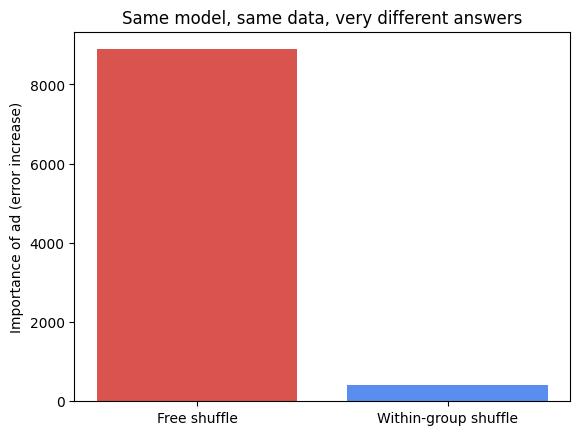

In [7]:
import matplotlib.pyplot as plt
plt.bar(['Free shuffle', 'Within-group shuffle'], [imp_free, imp_within], color=['#d9534f', '#5b8def'])
plt.ylabel('Importance of ad (error increase)')
plt.title('Same model, same data, very different answers')
plt.show()